# Practical - read the traffic light

A traffic-enforcement camera hangs over a junction. To catch a car running a red light, it has
to know - in every frame, in real time, on a cheap CPU, day and night, rain and sun - **what
state the signal is in**: red, yellow, green, or off.

Today we build that reader with **no learning at all**: only the tools from HW1b, HW1c and
[48]. Then we point it at five cameras it has never seen.

| Part | What we do | Tools |
|---|---|---|
| 1 | look at the data, split it honestly | |
| 2 | read the **colour** | HSV (HW1b Part 3) |
| 3 | find **which lamp is lit** | kernels, morphology, connected components ([48], HW1c) |
| 4 | combine two cues that fail differently | |
| 5 | the honesty test: five new cameras | |
| 6 | teaser: what does a CNN do here? | next practical |

**Runtime:** the whole notebook takes about half a minute on a laptop CPU; only the first cell
(imports) is noticeably slow.

**Data** (`data/`, 3.1 MB): 341 crops of traffic lights from **S2TLD**, a dashcam dataset
(day, dusk and night, every label checked by eye), and 153 crops from **5 public live cameras**
mounted over real junctions in Tokyo, Fresno, Nashville and Kingston.

## Setup

In [1]:
# ~5 s: the first import of cv2 and plotly is slow
import json
from collections import Counter
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import plotly.graph_objects as go

SEED = 509
CLASSES = ["red", "yellow", "green", "off"]
DATA = Path("data")
labels = json.loads((DATA / "labels.json").read_text(encoding="utf-8"))

Every crop is a small PNG. OpenCV loads images as **BGR** (blue first) - we convert to RGB only
for display.

In [2]:
def load(path):
    img = cv2.imread(str(path))
    if img is None:
        raise FileNotFoundError(path)
    return img


s2tld = [dict(r, img=load(DATA / "s2tld" / f"{r['crop_id']}.png")) for r in labels["s2tld"]]
cams = [dict(r, img=load(DATA / "cams" / r["cam"] / f"{r['key']}.png")) for r in labels["cams"]]
print(f"{len(s2tld)} dashcam crops, {len(cams)} junction-camera crops")
print("states:  ", dict(Counter(r["state"] for r in s2tld)))
print("lighting:", dict(Counter(r["lighting"] for r in s2tld)))

341 dashcam crops, 153 junction-camera crops
states:   {'green': 122, 'off': 17, 'red': 184, 'yellow': 18}
lighting: {'day': 172, 'dusk': 100, 'night': 69}


Two helpers: one draws a row of crops, one scores a rule. A **rule** is any function that takes
a crop and returns one of `red`, `yellow`, `green`, `off`.

In [3]:
def rgb(bgr):
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


def show(rows, title=None, size=1.0):
    # rows: list of (image_bgr, caption); the figure is as tall as the tallest crop needs
    tall = max(img.shape[0] / img.shape[1] for img, _ in rows)
    fig, axes = plt.subplots(1, len(rows), figsize=(size * len(rows), size * min(tall, 2.4) + 0.5),
                             squeeze=False)
    for ax, (img, cap) in zip(axes[0], rows):
        ax.imshow(rgb(img), interpolation="nearest")
        ax.set_title(cap, fontsize=8)
        ax.axis("off")
    if title:
        fig.suptitle(title, fontsize=10, y=1.04)
    plt.show()


def accuracy(rule, data):
    return float(np.mean([rule(r["img"]) == r["state"] for r in data]))


def report(rule, data, by="lighting"):
    preds = [rule(r["img"]) for r in data]
    ok = [p == r["state"] for p, r in zip(preds, data)]
    groups = sorted({r[by] for r in data})
    per = ", ".join(f"{g} {np.mean([o for o, r in zip(ok, data) if r[by] == g]):.0%}" for g in groups)
    print(f"accuracy {np.mean(ok):.1%}   ({per})")
    mistakes = Counter(f"{r['state']} -> {p}" for p, r in zip(preds, data) if p != r["state"])
    print("most common mistakes:", mistakes.most_common(4))
    return preds

# Part 1 - the data, and an honest split

What a crop looks like, two per state, for each lighting condition. They are **tiny**: the
middle crop is about 21 pixels wide.

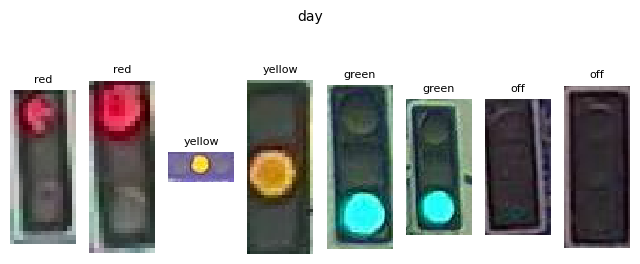

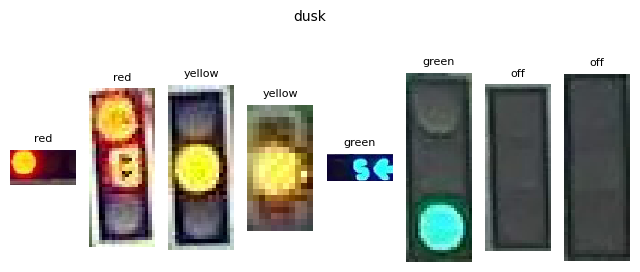

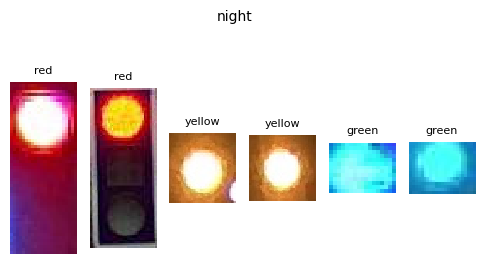

crop width, pixels: median 21 | height: median 41


In [4]:
for light in ("day", "dusk", "night"):
    rows = []
    for state in CLASSES:
        rows += [(r["img"], f"{state}") for r in s2tld if r["state"] == state and r["lighting"] == light][:2]
    show(rows, title=light)
print("crop width, pixels: median", int(np.median([r["img"].shape[1] for r in s2tld])),
      "| height: median", int(np.median([r["img"].shape[0] for r in s2tld])))

Where they come from: two of the dashcam frames, boxes drawn on.

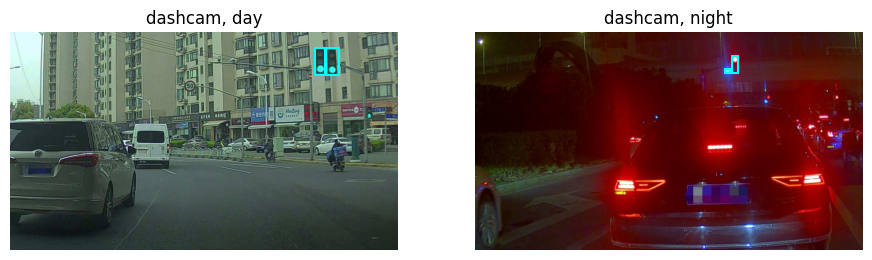

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, name in zip(axes, ["s2tld_day", "s2tld_night"]):
    frame = load(DATA / "context" / f"{name}.jpg")
    ax.imshow(rgb(frame))
    for x1, y1, x2, y2 in labels["context_boxes"][name]:
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="cyan", lw=1.5))
    ax.set_title(name.replace("s2tld_", "dashcam, "))
    ax.axis("off")
plt.show()

### Three levels of honesty

We will tune rules - thresholds, hue bands, how to combine cues. Every number we tune by looking
at errors leaks those errors into the rule. So the data is split three ways, and each part is
looked at differently:

- **tune** (60% of the dashcam frames): look at it as much as you like;
- **test** (the other 40%): the **same cameras**, other moments - looked at **once**, at the end
  of Part 4;
- **cams** (the 5 junction cameras): new cameras, new countries - sealed until Part 5.

The split is **by frame**: two lights in the same photo always land on the same side, otherwise
the test set would contain near-copies of tuning crops and flatter us ([08]: a validation set is
only honest if nothing in it was seen while tuning).

In [6]:
rng = np.random.default_rng(SEED)
frame_light = {r["frame_id"]: r["lighting"] for r in s2tld}
tune_frames = set()
for light in ("day", "dusk", "night"):          # stratified: every lighting on both sides
    frames = sorted(f for f, l in frame_light.items() if l == light)
    rng.shuffle(frames)
    tune_frames |= set(frames[:round(0.6 * len(frames))])
tune = [r for r in s2tld if r["frame_id"] in tune_frames]
test = [r for r in s2tld if r["frame_id"] not in tune_frames]
print(f"tune {len(tune)} crops {dict(Counter(r['state'] for r in tune))}")
print(f"test {len(test)} crops {dict(Counter(r['state'] for r in test))}")

tune 217 crops {'green': 70, 'off': 13, 'red': 124, 'yellow': 10}
test 124 crops {'red': 60, 'yellow': 8, 'green': 52, 'off': 4}


The baseline to beat: red is the most common state, so a rule that always says "red" is already
right more than half the time.

In [7]:
always_red = lambda bgr: "red"
print(f"always red: tune {accuracy(always_red, tune):.1%}, test {accuracy(always_red, test):.1%}")

always red: tune 57.1%, test 48.4%


# Part 2 - colour: HSV

From HW1b Part 3: in **HSV** the hue is "which colour", separate from how bright it is. OpenCV
stores hue as 0-179 (degrees divided by 2), so red sits at **both ends**: 0-10 and 170-179.

A lamp that is on is **bright** (high V) and **coloured** (high S). Below: the hue of every lit
pixel, per state, on the tune split. Shaded: the hue bands our rule will use.

In [8]:
def lit_mask(hsv):
    return (hsv[..., 1] > 70) & (hsv[..., 2] > 120)


fig = go.Figure()
for state, colour in [("red", "#D90012"), ("yellow", "#F2A800"), ("green", "#2e8b57")]:
    hues = np.concatenate([cv2.cvtColor(r["img"], cv2.COLOR_BGR2HSV)[..., 0][lit_mask(cv2.cvtColor(r["img"], cv2.COLOR_BGR2HSV))]
                           for r in tune if r["state"] == state])
    counts, edges = np.histogram(hues, bins=90, range=(0, 180))
    fig.add_trace(go.Scatter(x=edges[:-1], y=counts / counts.sum(), name=f"{state} lamps",
                             line=dict(color=colour, width=2)))
for lo, hi, colour in [(0, 10, "#D90012"), (170, 180, "#D90012"), (12, 34, "#F2A800"), (38, 100, "#2e8b57")]:
    fig.add_vrect(x0=lo, x1=hi, fillcolor=colour, opacity=0.08, line_width=0)
fig.update_layout(title="Hue of lit pixels, by true state (tune split)", xaxis_title="hue (OpenCV, 0-179)",
                  yaxis_title="share of lit pixels", height=360, width=820)
fig.show()

The rule: count the lit pixels in each hue band; the band with the most wins. If almost nothing
is lit, the light is **off**.

In [9]:
def colour_vote(bgr):
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    h = hsv[..., 0]
    lit = lit_mask(hsv)
    counts = {"red": int((lit & ((h <= 10) | (h >= 170))).sum()),
              "yellow": int((lit & (h >= 12) & (h <= 34)).sum()),
              "green": int((lit & (h >= 38) & (h <= 100)).sum())}
    best = max(counts, key=counts.get)
    if counts[best] < max(6, 0.004 * h.size):      # too little lit colour: the light is off
        return "off"
    return best


_ = report(colour_vote, tune)

accuracy 90.3%   (day 95%, dusk 85%, night 85%)
most common mistakes: [('red -> yellow', 19), ('red -> off', 1), ('off -> green', 1)]


About 90% from three hue bands. The mistakes are almost all one kind: **red lamps read as
yellow**, mostly at dusk and night. Let us look at them.

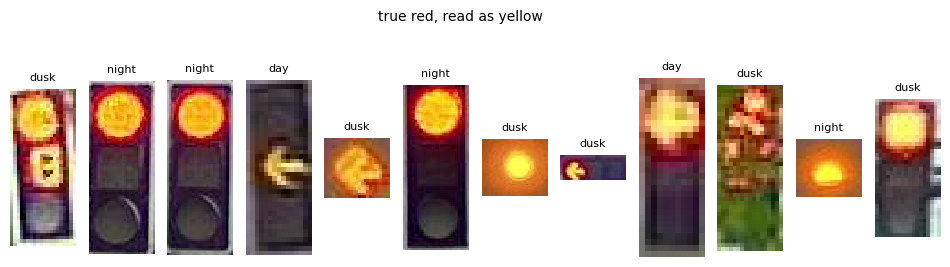

19 reds read as yellow: median lit hue 15
reds read correctly: share of lit pixels inside the red band 70%


In [10]:
red_as_yellow = [r for r in tune if r["state"] == "red" and colour_vote(r["img"]) == "yellow"]
show([(r["img"], r["lighting"]) for r in red_as_yellow[:12]], title="true red, read as yellow")


def lit_hues(rows):
    out = []
    for r in rows:
        hsv = cv2.cvtColor(r["img"], cv2.COLOR_BGR2HSV)
        out.append(hsv[..., 0][lit_mask(hsv)])
    return np.concatenate(out)


right_reds = [r for r in tune if r["state"] == "red" and colour_vote(r["img"]) == "red"]
print(f"{len(red_as_yellow)} reds read as yellow: median lit hue {np.median(lit_hues(red_as_yellow)):.0f}")
print(f"reds read correctly: share of lit pixels inside the red band "
      f"{np.mean(np.isin(lit_hues(right_reds), list(range(0, 11)) + list(range(170, 180)))):.0%}")

A bright red LED **bleeds into orange**: its lit pixels sit around hue 15-20, inside the yellow
band. Moving the band edge does not help - real yellows live there too. The colour alone cannot
tell an orange-looking red from a yellow.

We need a **second cue that does not look at hue at all**.

# Part 3 - which lamp is lit?

A vertical traffic light has **red on top, yellow in the middle, green at the bottom**; the
horizontal ones in this dataset run red, yellow, green from left to right. Find the lit lamp,
and you know the state without reading its colour.

Step 1: a **brightness map**. A lit lamp is bright, and either coloured (daytime) or extremely
bright (night glare):

$$E = V \cdot (0.4 + 0.6 \cdot S/255)$$

In [11]:
def energy(bgr):
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV).astype(np.float32)
    return hsv[..., 2] * (0.4 + 0.6 * hsv[..., 1] / 255)

Steps 2-5 are this lecture and HW1c:

2. **Gaussian blur** - a 3x3 kernel ([48]'s kernel zoo) so a single hot pixel cannot win;
3. **threshold** at 60% of the brightest value - the lit region;
4. **opening** = erosion, then dilation ([48]) - removes specks;
5. **connected components** (HW1c) - keep the largest blob, take its centre.

Where the centre sits along the housing (top / middle / bottom third) is the answer.

In [12]:
def lit_region(bgr, blur=True, opening=True):
    e = energy(bgr)
    if blur:
        e = cv2.GaussianBlur(e, (3, 3), 0)
    mask = (e >= 0.6 * e.max()).astype(np.uint8)
    if opening:
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))
    return e, mask


def position_vote(bgr, blur=True, opening=True):
    e, mask = lit_region(bgr, blur, opening)
    if e.max() < 90 or mask.sum() == 0:          # nothing bright: off
        return "off"
    _, _, stats, centres = cv2.connectedComponentsWithStats(mask)
    k = 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))     # largest blob (0 is background)
    cx, cy = centres[k]
    h, w = mask.shape
    where = cy / h if h >= w else cx / w        # 0 = top / left, 1 = bottom / right
    return CLASSES[min(2, int(where * 3))]      # thirds: red, yellow, green

The pipeline on three tune crops: the crop, its brightness map, the lit region after opening,
and the verdict.

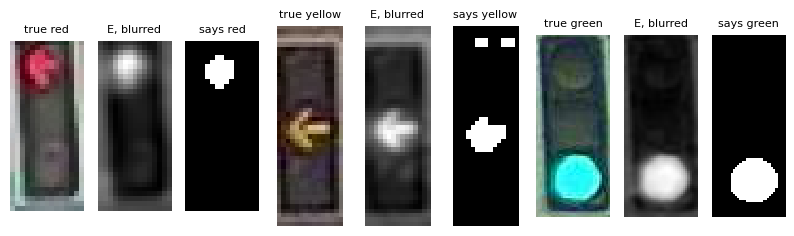

In [13]:
picks = [next(r for r in tune if r["state"] == s and r["lighting"] == "day") for s in ("red", "yellow", "green")]
fig, axes = plt.subplots(1, 9, figsize=(10, 2.6))
for i, r in enumerate(picks):
    e, mask = lit_region(r["img"])
    axes[3 * i].imshow(rgb(r["img"]), interpolation="nearest"); axes[3 * i].set_title(f"true {r['state']}", fontsize=8)
    axes[3 * i + 1].imshow(e, cmap="gray", interpolation="nearest"); axes[3 * i + 1].set_title("E, blurred", fontsize=8)
    axes[3 * i + 2].imshow(mask, cmap="gray", interpolation="nearest")
    axes[3 * i + 2].set_title(f"says {position_vote(r['img'])}", fontsize=8)
for ax in axes:
    ax.axis("off")
plt.show()

In [14]:
_ = report(position_vote, tune)

accuracy 76.5%   (day 83%, dusk 88%, night 41%)
most common mistakes: [('red -> yellow', 33), ('green -> yellow', 15), ('off -> red', 1), ('green -> red', 1)]


Worse than colour overall, and terrible at night. Did the kernels earn their place? Measure it:
switch the blur and the opening off, one at a time.

In [15]:
for blur in (True, False):
    for opening in (True, False):
        acc = accuracy(lambda b: position_vote(b, blur, opening), tune)
        print(f"blur {str(blur):5s} opening {str(opening):5s} -> {acc:.1%}")

blur True  opening True  -> 76.5%


blur True  opening False -> 77.0%


blur False opening True  -> 75.6%


blur False opening False -> 76.5%


**Within about one point either way.** On crops 21 pixels wide a 3x3 blur and a 2x2 opening
change very little - the connected component is doing the work. Worth knowing: a step that is
"standard" is not automatically a step that helps. Measure it.

Now the night failures:

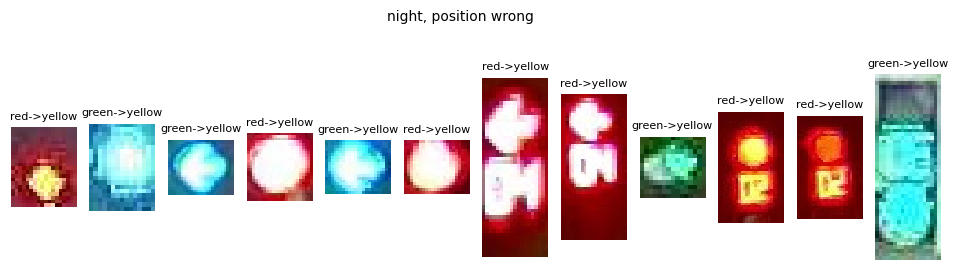

In [16]:
night_bad = [r for r in tune if r["lighting"] == "night" and position_vote(r["img"]) != r["state"]]
show([(r["img"], f"{r['state']}->{position_vote(r['img'])}") for r in night_bad[:12]],
     title="night, position wrong")

At night the lamp **blooms**: its glare fills the whole housing, so the "largest bright blob" is
the entire light and its centre is always the middle. Position is blind exactly where colour is
strong (a night red is unmistakably red) - and colour is weak exactly where position is fine.

# Part 4 - two cues that fail differently

Count it: on the tune split, which crops does each cue get right?

In [17]:
table = Counter((colour_vote(r["img"]) == r["state"], position_vote(r["img"]) == r["state"]) for r in tune)
for (c_ok, p_ok), n in sorted(table.items(), reverse=True):
    print(f"colour {'right' if c_ok else 'wrong':5s}  position {'right' if p_ok else 'wrong':5s}: {n}")

colour right  position right: 150
colour right  position wrong: 46
colour wrong  position right: 16
colour wrong  position wrong: 5


Only a handful of crops fool **both**. So a rule that knows when to trust which cue could be right
almost everywhere. Ours, in five lines:

- they agree - done;
- position finds no clear lamp - trust colour;
- colour finds no lit colour - trust position;
- colour says **yellow** but the lit lamp is the **top** one - it is an orange-looking red;
- otherwise colour, the stronger cue.

In [18]:
def fused(bgr):
    c, p = colour_vote(bgr), position_vote(bgr)
    if c == p:
        return c
    if p == "off":
        return c
    if c == "off":
        return p
    if c == "yellow" and p == "red":
        return "red"
    return c


_ = report(fused, tune)

accuracy 97.2%   (day 97%, dusk 97%, night 98%)
most common mistakes: [('red -> yellow', 4), ('off -> green', 1), ('off -> yellow', 1)]


For comparison: the rule from the project this practical grew out of. An expert tuned it **after
looking at every error on the full dashcam set** - a different position cue (energy per housing
third), a hue vote restricted to the lit third, and two extra special cases for amber-cored red
LEDs. It is printed here so that the comparison is fair; read it, do not memorise it.

In [19]:
def _cell_scores(bgr):
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    e = hsv[..., 2].astype(np.float32) * (0.4 + 0.6 * hsv[..., 1].astype(np.float32) / 255)
    vertical = bgr.shape[0] >= bgr.shape[1]
    cells = np.array_split(e, 3, axis=0 if vertical else 1)
    return [float(np.mean(np.sort(c.ravel())[-max(1, c.size // 10):])) for c in cells], vertical


def _hue_counts(bgr):
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    h = hsv[..., 0][(hsv[..., 2] > 110) & (hsv[..., 1] > 60)]
    return {"red": int(((h <= 12) | (h >= 168)).sum()), "yellow": int(((h >= 14) & (h <= 34)).sum()),
            "green": int(((h >= 38) & (h <= 100)).sum())}


def expert(bgr):
    scores, vertical = _cell_scores(bgr)
    order = np.argsort(scores)[::-1]
    win = int(order[0])
    lit = scores[win] >= 90 and scores[win] / max(scores[order[1]], 1e-6) >= 1.15
    idx = np.array_split(np.arange(bgr.shape[0] if vertical else bgr.shape[1]), 3)[win]
    cell = bgr[idx[0]:idx[-1] + 1] if vertical else bgr[:, idx[0]:idx[-1] + 1]
    counts = _hue_counts(cell if lit else bgr)
    best = max(counts, key=counts.get)
    if counts[best] < 6:
        if not lit:
            return "off"
        top, second = scores[order[0]], scores[order[1]]
        return "off" if top < 90 or top / max(second, 1e-6) < 1.18 else CLASSES[win]
    if best == "yellow" and counts["red"] >= 0.35 * counts["yellow"]:
        return "red"
    if best == "yellow" and lit and vertical and win == 0:
        return "red"
    return best


_ = report(expert, tune)

accuracy 98.6%   (day 97%, dusk 100%, night 100%)
most common mistakes: [('off -> green', 1), ('red -> green', 1), ('red -> yellow', 1)]


The expert's rule wins on the tune split. Now - **once** - the test split: same cameras, moments
**we** never looked at. (The expert did: their rule was written while looking at all 341 dashcam
crops, test half included. Keep that in mind.)

In [20]:
RULES = {"colour": colour_vote, "position": position_vote, "fused (ours)": fused, "expert": expert}
results = {name: {"tune": accuracy(rule, tune), "test": accuracy(rule, test)} for name, rule in RULES.items()}
for name, r in results.items():
    print(f"{name:13s} tune {r['tune']:.1%}   test {r['test']:.1%}")

colour        tune 90.3%   test 88.7%
position      tune 76.5%   test 74.2%
fused (ours)  tune 97.2%   test 96.8%
expert        tune 98.6%   test 96.0%


Our five lines hold their ground on crops they never saw. The expert's rule, written while
looking at these very crops, does **no better** here. Its extra special cases did not buy
accuracy; they bought a closer fit to one dataset. Every hand-tuned constant is a small bet that
the next images look like the ones you tuned on.

Which brings us to the real test.

# Part 5 - the honesty test: five new cameras

The deployment camera does not ride on a car's dashboard: it hangs on a pole over the junction.
These five are public live cameras with exactly that view. Each signal head was located once per
camera (that is how a real installation is set up), then each frame's state labelled by hand.

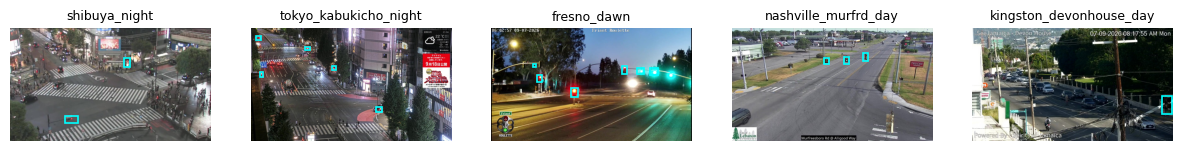

{'shibuya_night': 12, 'tokyo_kabukicho_night': 40, 'fresno_dawn': 36, 'nashville_murfrd_day': 60, 'kingston_devonhouse_day': 5}


In [21]:
names = [n for n in labels["context_boxes"] if n.startswith("cam_")]
fig, axes = plt.subplots(1, len(names), figsize=(15, 2.6))
for ax, name in zip(axes, names):
    frame = load(DATA / "context" / f"{name}.jpg")
    ax.imshow(rgb(frame))
    for x1, y1, x2, y2 in labels["context_boxes"][name]:
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec="cyan", lw=1.2))
    ax.set_title(name[4:], fontsize=9)
    ax.axis("off")
plt.show()
print(dict(Counter(r["cam"] for r in cams)))

Every rule, unchanged, on the new cameras:

In [22]:
for name, rule in RULES.items():
    results[name]["cams"] = accuracy(rule, cams)
    print(f"{name:13s} cams {results[name]['cams']:.1%}")
    per_cam = ", ".join(f"{c} {np.mean([rule(r['img']) == r['state'] for r in cams if r['cam'] == c]):.0%}"
                        for c in sorted({r["cam"] for r in cams}))
    print(f"{'':13s} {per_cam}")

colour        cams 71.2%
              fresno_dawn 100%, kingston_devonhouse_day 20%, nashville_murfrd_day 33%, shibuya_night 100%, tokyo_kabukicho_night 100%
position      cams 6.5%


              fresno_dawn 17%, kingston_devonhouse_day 80%, nashville_murfrd_day 0%, shibuya_night 0%, tokyo_kabukicho_night 0%


fused (ours)  cams 72.5%


              fresno_dawn 100%, kingston_devonhouse_day 60%, nashville_murfrd_day 33%, shibuya_night 100%, tokyo_kabukicho_night 100%


expert        cams 59.5%


              fresno_dawn 100%, kingston_devonhouse_day 60%, nashville_murfrd_day 0%, shibuya_night 100%, tokyo_kabukicho_night 100%


All four numbers side by side:

In [23]:
fig = go.Figure()
for split, colour in [("tune", "#9aa5b8"), ("test", "#0033A0"), ("cams", "#D90012")]:
    vals = [100 * results[n][split] for n in RULES]
    fig.add_trace(go.Bar(name=split, x=list(RULES), y=vals, marker_color=colour,
                         text=[f"{v:.0f}%" for v in vals], textposition="outside"))
fig.update_layout(barmode="group", yaxis=dict(title="accuracy (%)", range=[0, 110]), height=380,
                  width=820, title="Tuned here, tested there")
fig.show()

**Position collapses** on the new cameras. Look at the two Tokyo cameras' horizontal lights:

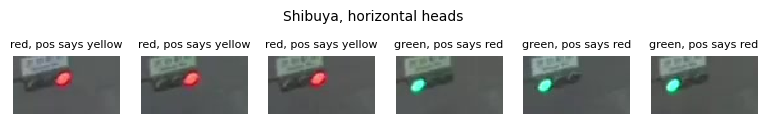

In [24]:
tokyo = [r for r in cams if r["cam"] == "shibuya_night" and r["img"].shape[1] > r["img"].shape[0]]
show([(r["img"], f"{r['state']}, pos says {position_vote(r['img'])}") for r in tokyo[:6]], size=1.6,
     title="Shibuya, horizontal heads")

Japanese horizontal lights put **green on the left** and red on the right - the opposite of the
dashcam data. The position rule is not wrong about where the lamp is; it is wrong about the
**world**. Its "red is first" constant was a fact about one country.

Colour, meanwhile, is perfect at night on these cameras and falls apart in daylight at the
Nashville camera:

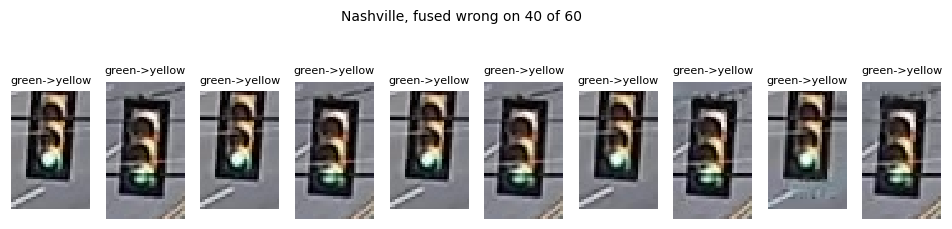

In [25]:
nash = [r for r in cams if r["cam"] == "nashville_murfrd_day" and fused(r["img"]) != r["state"]]
show([(r["img"], f"{r['state']}->{fused(r['img'])}") for r in nash[:10]], size=1.2,
     title=f"Nashville, fused wrong on {len(nash)} of {sum(r['cam'] == 'nashville_murfrd_day' for r in cams)}")

Low sun shines **into the unlit amber lens** and makes it glow - a "sun phantom". Now two lamps
look lit and the yellow one wins the hue vote.

What a real system does about it (none of it is a better threshold):

- **calibrate per site**: which lamp is where, once per camera - fixes the Tokyo flip outright;
- **smooth over time**: a phantom glow is constant all afternoon, a real light changes every
  cycle;
- **allow "unknown"**: some frames are unreadable even for a human (one camera in the original
  project showed all lamps glowing at once in haze). An honest system says so.

# Part 6 - teaser: what about learning?

The project this practical grew out of also trained a **tiny CNN** (about 25,000 weights, 32x32
input) on other frames from the same dashcam cameras. Its measured numbers:

In [26]:
cnn = json.loads((DATA / "cnn_reference.json").read_text(encoding="utf-8"))
print(f"tiny CNN, dashcam crops: {cnn['s2tld']['accuracy']:.1%}  (ours, fused: tune+test "
      f"{accuracy(fused, s2tld):.1%})")
print(f"tiny CNN, new cameras:   {cnn['cams']['accuracy']:.1%}  (ours, fused: {results['fused (ours)']['cams']:.1%})")
print("per camera:", {k: f"{v:.0%}" for k, v in cnn["cams"]["by_cam"].items()})

tiny CNN, dashcam crops: 99.4%  (ours, fused: tune+test 97.1%)
tiny CNN, new cameras:   51.0%  (ours, fused: 72.5%)
per camera: {'fresno_dawn': '100%', 'kingston_devonhouse_day': '40%', 'nashville_murfrd_day': '0%', 'shibuya_night': '0%', 'tokyo_kabukicho_night': '100%'}


Near-perfect where it was trained - and **worse than our five lines** on cameras it has never
seen. Learning does not make the new-camera problem go away. What it changes is the price of
the fix: instead of rewriting rules for every junction, you **label a few hundred crops from the
new camera and retrain**.

That is the next practical: train a CNN yourself - and see what it learns, and where it breaks.

## What we used, and where it came from

| tool | from | what it did here |
|---|---|---|
| HSV, hue bands | HW1b Part 3 | read the colour - 90% alone |
| Gaussian blur, opening | [48] (kernel zoo, dilation and erosion) | measured: barely mattered on tiny crops |
| connected components | HW1c Task 5 | found the lit lamp |
| tune / test / sealed split | [08] validation | caught the expert rule's overfitting |
| per-site calibration, temporal smoothing | - | what production actually needs |